# Detecting a severity change while stimulation is running

Runs top to bottom unattended. Sections 1-3 read caches and take about a minute.
Sections 4 and 5 each simulate 40 brains, about 37 minutes each, and cache as they go
so a re-run is free.

**Two questions:**

1. Does a severity change stay visible while a controller is stimulating?
2. How small a change can we still see?

**Two detectors, both causal** — at each step they see only the data up to that point:

- **changepoint**, a max-split Welch *t*-statistic
- **k-means**, two-cluster with a contiguity rule

Both thresholds are calibrated once in section 2 on the unstimulated `pd = 0.3 -> 0.7`
brains and then **frozen**. Nothing downstream re-tunes them.

---

## How to read the results, decided in advance

The headline number is **separation** — the P_beta change in units of within-segment
standard deviation. It is threshold-free, so it measures whether a signal exists at all,
independently of whether one particular detector setting happened to catch it.

| separation | meaning |
|---|---|
| **>= 3.0** | detectable; a working detector is expected |
| **2.0 - 3.0** | marginal; detectable on some brains, not reliably |
| **< 2.0** | below the resolution of this method |

Detection counts are reported alongside, using the frozen thresholds. Where separation is
high and detection is low, the threshold is the problem. Where separation is low, nothing
rescues it.

**For section 4 and 5, every outcome is a result:**

- If separation stays above 3 down to a 0.1 step, the method resolves fine-grained
  severity change — the strongest claim available.
- If it falls below 3 somewhere in the ladder, that crossing point **is** the answer:
  "this method resolves severity steps of about X." A resolution limit is a
  specification, not a failure, and it is the number a reviewer will ask for.
- If the stimulated row sits well below the unstimulated row, stimulation costs
  resolution, and the gap between the two rows quantifies the cost.

> Restart the kernel after editing any `.py` file.

## 1 · Setup

In [1]:
import json
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image

import helpers
import pd_switch as ps

eng = ps.start_engine(code_dir=".", matlab_dir="matlab")
print("engine up")

SUMMARY = {}

def load_cached(out_dir):
    out = {}
    for p in sorted(Path(out_dir).glob("seed*.npz"), key=lambda q: int(q.stem[4:])):
        d = np.load(p)
        out[int(p.stem[4:])] = (d["times"], d["values"])
    return out

def pair_average(results):
    out = {}
    for s, (t, v) in results.items():
        m = (len(v) // 2) * 2
        out[s] = ((t[:m:2] + t[1:m:2]) / 2.0, (v[:m:2] + v[1:m:2]) / 2.0)
    return out

def infer_switch(results):
    t = next(iter(results.values()))[0]
    return float((t[0] + t[-1]) / 2.0)

def stats(results, switch_s=None):
    if switch_s is None:
        switch_s = infer_switch(results)
    gaps, seps = ps.summarize(results, switch_s=switch_s)
    n = len(gaps)
    return {
        "n": n,
        "gap": float(gaps.mean()),
        "gap_sem": float(gaps.std(ddof=1) / np.sqrt(n)),
        "sep": float(seps.mean()),
        "sep_sem": float(seps.std(ddof=1) / np.sqrt(n)),
        "sep_worst": float(seps.min()),
    }

def verdict(sep):
    if sep >= 3.0:
        return "detectable"
    if sep >= 2.0:
        return "marginal"
    return "below resolution"

print("helpers defined")

engine up
helpers defined


## 2 · Calibrate both detectors, then freeze

Seeds 1-10 of the unstimulated `0.3 -> 0.7` set. For each detector the chosen value is
the **midpoint of the range that gives no false alarms and no misses**, which is more
robust than the first value that happens to pass.

Thresholds are chosen here and never touched again.

In [2]:
cal = {s: v for s, v in load_cached("runs_switch").items() if s <= 10}
if not cal:
    raise SystemExit("no runs_switch/ cache — run the unstimulated 0.3->0.7 seeds first")
cal_par = pair_average(cal)

def pick(label, detector, grid, key, series, **fixed):
    clean = []
    for x in grid:
        r = ps.evaluate(series, detector, **{key: x}, **fixed)
        ok = not r["false"] and not r["missed"]
        if ok:
            clean.append(x)
        print(f"  {key} {x:5.2f}  ok {r['ok']:2d}/{r['n']}  "
              f"false {r['false']}  missed {r['missed']}")
    if not clean:
        print(f"  !! no clean value for {label}; falling back")
        return None
    chosen = round(float(np.median(clean)), 3)
    print(f"  -> {label}: {chosen}\n")
    return chosen

print("changepoint, raw series")
CP_RAW = pick("CP_RAW", ps.detect_cp, (4.0, 5.0, 6.0, 7.0, 8.0, 9.0),
              "thresh", cal, min_size=4) or 7.0

print("changepoint, paired series")
CP_PAIR = pick("CP_PAIR", ps.detect_cp, (3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 8.0),
               "thresh", cal_par, min_size=3) or 5.75

print("k-means, paired series")
KM_GAP = pick("KM_GAP", ps.detect_kmeans, (0.04, 0.06, 0.08, 0.10, 0.13, 0.16, 0.20, 0.25),
              "min_gap", cal_par, max_breaks=6, min_size=3) or 0.13

SUMMARY["thresholds"] = {"cp_raw": CP_RAW, "cp_paired": CP_PAIR, "km_min_gap": KM_GAP}
print(f"frozen: cp_raw={CP_RAW}  cp_paired={CP_PAIR}  km_min_gap={KM_GAP}")

changepoint, raw series
  thresh  4.00  ok  7/10  false [4, 5, 6]  missed []
  thresh  5.00  ok  7/10  false [4, 5, 6]  missed []
  thresh  6.00  ok 10/10  false []  missed []
  thresh  7.00  ok 10/10  false []  missed []
  thresh  8.00  ok 10/10  false []  missed []
  thresh  9.00  ok  9/10  false []  missed [1]
  -> CP_RAW: 7.0

changepoint, paired series
  thresh  3.00  ok  7/10  false [3, 5, 6]  missed []
  thresh  3.50  ok  9/10  false [6]  missed []
  thresh  4.00  ok 10/10  false []  missed []
  thresh  4.50  ok 10/10  false []  missed []
  thresh  5.00  ok 10/10  false []  missed []
  thresh  5.50  ok 10/10  false []  missed []
  thresh  6.00  ok 10/10  false []  missed []
  thresh  6.50  ok 10/10  false []  missed []
  thresh  7.00  ok 10/10  false []  missed []
  thresh  8.00  ok 10/10  false []  missed []
  -> CP_PAIR: 5.75

k-means, paired series
  min_gap  0.04  ok  3/10  false [2, 3, 4, 5, 7, 9, 10]  missed []
  min_gap  0.06  ok  6/10  false [2, 4, 5, 7]  missed []
  min

### The unstimulated baseline, all 30 brains

Held out: seeds 11-30 were never seen during calibration.

In [3]:
base = load_cached("runs_switch")
hold = {s: v for s, v in base.items() if s >= 11}
base_st = stats(base)
SUMMARY["baseline_0.3to0.7_nostim"] = base_st

print(f"30 brains   gap {base_st['gap']:+.1f}% +/- {base_st['gap_sem']:.1f}   "
      f"separation {base_st['sep']:.2f} +/- {base_st['sep_sem']:.2f}   "
      f"worst {base_st['sep_worst']:.2f}")
print(f"verdict: {verdict(base_st['sep'])}\n")

print("held out, seeds 11-30")
for lab, det, series, kw in [
    ("changepoint raw", ps.detect_cp, hold, {"thresh": CP_RAW}),
    ("changepoint paired", ps.detect_cp, pair_average(hold), {"thresh": CP_PAIR, "min_size": 3}),
    ("k-means paired", ps.detect_kmeans, pair_average(hold),
     {"min_gap": KM_GAP, "max_breaks": 6, "min_size": 3}),
]:
    r = ps.evaluate(series, det, **kw)
    ps.report("  " + lab, r)
    SUMMARY.setdefault("baseline_detectors", {})[lab] = {
        "ok": r["ok"], "n": r["n"], "latency": r["latency"]}

30 brains   gap +23.4% +/- 1.6   separation 5.10 +/- 0.36   worst 1.67
verdict: detectable

held out, seeds 11-30
  changepoint raw            ok 19/20  false [15]  missed []  latency 1.25s +/- 0.09
  changepoint paired         ok 20/20  false []  missed []  latency 1.68s +/- 0.11
  k-means paired             ok 17/20  false [23]  missed [18, 30]  latency 1.57s +/- 0.16


## 3 · Question 1 — does detection survive stimulation?

Reads the `runs_stim_*` caches already on disk. No simulation.

P_beta is computed on a 1000 ms window stepped 250 ms. At high amplitude that series
picks up a period-2 component which inflates the within-segment standard deviation
without moving either segment mean — so separation collapses while the real change is
untouched. Averaging adjacent windows cancels a period-2 component exactly, at the cost
of halving the time resolution.

The `gain` column is the diagnostic: **around 1.2x means no artifact, 2x or more means
there is one.**

In [4]:
rows = []
dirs = sorted(p for p in Path(".").glob("runs_stim_*") if p.is_dir())

print(f"{'run':<30}{'sep raw':>9}{'sep pair':>10}{'gain':>7}"
      f"{'cp':>8}{'kmeans':>9}{'cp lat':>10}")
print("-" * 83)
for d in dirs:
    raw = load_cached(d)
    if not raw:
        continue
    par = pair_average(raw)
    sw = infer_switch(raw)
    sr, sp = stats(raw, sw), stats(par, sw)
    rc = ps.evaluate(par, ps.detect_cp, thresh=CP_PAIR, min_size=3, switch_s=sw)
    rk = ps.evaluate(par, ps.detect_kmeans, min_gap=KM_GAP, max_breaks=6,
                     min_size=3, switch_s=sw)
    lat = f"{rc['latency']:.2f}s" if rc["ok"] else "-"
    print(f"{d.name:<30}{sr['sep']:9.2f}{sp['sep']:10.2f}"
          f"{sp['sep'] / sr['sep']:6.2f}x{rc['ok']:5d}/{rc['n']:<2}"
          f"{rk['ok']:6d}/{rk['n']:<2}{lat:>10}")
    rows.append({"run": d.name, "n": sr["n"], "switch_s": sw, "sep_raw": sr["sep"],
                 "sep_paired": sp["sep"], "gain": sp["sep"] / sr["sep"],
                 "cp_ok": rc["ok"], "km_ok": rk["ok"], "cp_latency": rc["latency"],
                 "verdict": verdict(sp["sep"])})

SUMMARY["under_stimulation"] = rows
if not rows:
    print("no runs_stim_*/ caches found — section 3 skipped")

run                             sep raw  sep pair   gain      cp   kmeans    cp lat
-----------------------------------------------------------------------------------
runs_stim_a0                       5.04      5.93  1.18x   10/10     8/10     1.98s
runs_stim_a1000                    1.46      3.17  2.17x    8/10     4/10     3.19s
runs_stim_a250                     3.93      4.51  1.15x    9/10     4/10     2.40s
runs_stim_a3500                    1.43      2.87  2.00x    9/10     4/10     3.29s
runs_stim_a500                     5.50      7.25  1.32x   10/10     3/10     1.82s
runs_stim_long_a3500               2.01      3.16  1.57x   10/10     0/10     2.62s


## 4 · Question 2 — how small a change can we see?

`pd` starts at 0.5 every time and steps up by 0.1, 0.2, 0.3 or 0.4. Holding the start
fixed means the only thing varying is the size of the change, so the result is a
resolution curve rather than four unrelated conditions.

Unstimulated first, to establish whether the signal exists before asking what
stimulation does to it.

**One thing to watch when reading the k-means column.** Its `min_gap` parameter is a
*relative* floor — it refuses to call two clusters distinct unless their centres differ
by that fraction. It was calibrated on a 23% step, so it lands somewhere near 0.13-0.15,
and it therefore **cannot fire on any condition whose `gap` is below that**, however
clean the data. Compare the printed `gap` against the frozen `min_gap`: where gap is
smaller, k-means is structurally blocked rather than outperformed, and the changepoint
comparison is not a fair one. That is a limitation of this parameterisation, not of
clustering as an approach.

**40 simulations, about 37 minutes.** Cached per condition.

In [5]:
STEPS = [(0.5, 0.6), (0.5, 0.7), (0.5, 0.8), (0.5, 0.9)]
SEEDS = range(1, 11)

def ladder(tag, freq, amp):
    out = []
    for pd_a, pd_b in STEPS:
        d = f"runs_ladder_{tag}_{pd_a}to{pd_b}"
        res, _ = ps.run_seeds(eng, SEEDS, helpers.calculate_pb, out_dir=d,
                              pd_start=pd_a, pd_end=pd_b,
                              warmup_ms=2000, hold_ms=5000,
                              freq=freq, amp=amp, verbose=False)
        par = pair_average(res)
        sr, sp = stats(res), stats(par)
        rc = ps.evaluate(par, ps.detect_cp, thresh=CP_PAIR, min_size=3)
        rk = ps.evaluate(par, ps.detect_kmeans, min_gap=KM_GAP, max_breaks=6, min_size=3)
        row = {"step": round(pd_b - pd_a, 2), "pd_start": pd_a, "pd_end": pd_b,
               "n": sr["n"], "gap": sr["gap"], "gap_sem": sr["gap_sem"],
               "sep": sr["sep"], "sep_sem": sr["sep_sem"], "sep_worst": sr["sep_worst"],
               "sep_paired": sp["sep"], "cp_ok": rc["ok"], "km_ok": rk["ok"],
               "verdict": verdict(sr["sep"])}
        out.append(row)
        print(f"  {pd_a} -> {pd_b}  (step {row['step']:.1f})  "
              f"gap {row['gap']:+6.1f}% +/- {row['gap_sem']:4.1f}   "
              f"sep {row['sep']:5.2f} +/- {row['sep_sem']:4.2f}   "
              f"cp {rc['ok']:2d}/{rc['n']}  km {rk['ok']:2d}/{rk['n']}   "
              f"{row['verdict']}")
    return out

print("unstimulated (amp = 0)")
lad_nostim = ladder("nostim", 130.0, 0.0)
SUMMARY["ladder_nostim"] = lad_nostim

unstimulated (amp = 0)
  0.5 -> 0.6  (step 0.1)  gap   +2.0% +/-  0.5   sep  0.64 +/- 0.16   cp  2/10  km  0/10   below resolution
  0.5 -> 0.7  (step 0.2)  gap   +3.1% +/-  1.0   sep  0.81 +/- 0.26   cp  1/10  km  0/10   below resolution
  0.5 -> 0.8  (step 0.3)  gap   +3.9% +/-  1.1   sep  1.01 +/- 0.27   cp  1/10  km  1/10   below resolution
  0.5 -> 0.9  (step 0.4)  gap   +5.5% +/-  1.3   sep  1.44 +/- 0.41   cp  4/10  km  2/10   below resolution


## 5 · The same ladder with the controller running

180 Hz / 500 µA — the setting all three trained agents converged on, so this is the
operating point that matters rather than an arbitrary amplitude.

**40 simulations, about 37 minutes.**

In [6]:
print("stimulated (180 Hz / 500 uA)")
lad_stim = ladder("stim180_500", 180.0, 500.0)
SUMMARY["ladder_stim_180hz_500ua"] = lad_stim

stimulated (180 Hz / 500 uA)
  0.5 -> 0.6  (step 0.1)  gap  +15.4% +/-  2.7   sep  1.56 +/- 0.27   cp  3/10  km  5/10   below resolution
  0.5 -> 0.7  (step 0.2)  gap  +35.6% +/-  3.8   sep  3.68 +/- 0.36   cp 10/10  km  6/10   detectable
  0.5 -> 0.8  (step 0.3)  gap  +40.5% +/-  6.6   sep  3.88 +/- 0.59   cp  9/10  km  5/10   detectable
  0.5 -> 0.9  (step 0.4)  gap  +22.8% +/-  9.6   sep  1.76 +/- 0.92   cp  6/10  km  6/10   below resolution


## 6 · The resolution curve

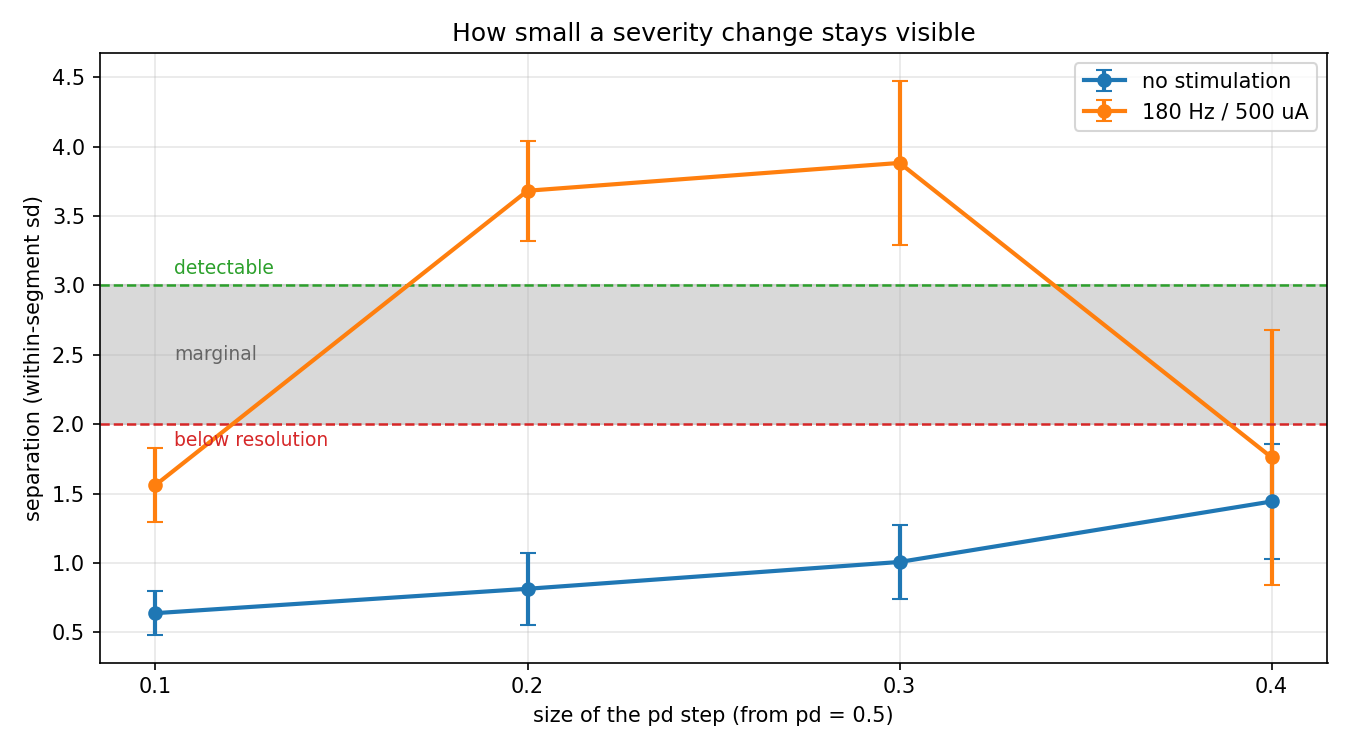

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for lab, lad, c in [("no stimulation", lad_nostim, "tab:blue"),
                    ("180 Hz / 500 uA", lad_stim, "tab:orange")]:
    x = [r["step"] for r in lad]
    y = [r["sep"] for r in lad]
    e = [r["sep_sem"] for r in lad]
    ax.errorbar(x, y, yerr=e, marker="o", lw=2, capsize=4, color=c, label=lab)

ax.axhspan(2.0, 3.0, color="0.85", zorder=0)
ax.axhline(3.0, ls="--", lw=1.2, color="tab:green")
ax.axhline(2.0, ls="--", lw=1.2, color="tab:red")
ax.text(0.105, 3.05, "detectable", color="tab:green", fontsize=9, va="bottom")
ax.text(0.105, 1.95, "below resolution", color="tab:red", fontsize=9, va="top")
ax.text(0.105, 2.5, "marginal", color="0.4", fontsize=9, va="center")
ax.set_xlabel("size of the pd step (from pd = 0.5)")
ax.set_ylabel("separation (within-segment sd)")
ax.set_title("How small a severity change stays visible")
ax.set_xticks([r["step"] for r in lad_nostim])
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("fig_resolution.png", dpi=150)
plt.close(fig)
Image("fig_resolution.png")

## 7 · Summary

Everything above, in one block. Paste this output into the chat and it becomes the
meeting write-up.

In [8]:
def smallest_detectable(lad):
    ok = [r["step"] for r in lad if r["sep"] >= 3.0]
    return min(ok) if ok else None

res_nostim = smallest_detectable(lad_nostim)
res_stim = smallest_detectable(lad_stim)
SUMMARY["resolution"] = {"nostim_smallest_step": res_nostim,
                         "stim_smallest_step": res_stim}

print("=" * 66)
print("DETECTING A SEVERITY CHANGE UNDER STIMULATION")
print("=" * 66)
print()
print("SETUP")
print("  basal-ganglia-thalamic model, pd switched mid-simulation, state preserved")
print("  P_beta 13-35 Hz, 1000 ms window stepped 250 ms, 2 s warm-up discarded")
print(f"  frozen thresholds: cp_raw {CP_RAW}  cp_paired {CP_PAIR}  km_min_gap {KM_GAP}")
print()
print("BASELINE  pd 0.3 -> 0.7, no stimulation")
b = SUMMARY["baseline_0.3to0.7_nostim"]
print(f"  {b['n']} brains   gap {b['gap']:+.1f}% +/- {b['gap_sem']:.1f}   "
      f"separation {b['sep']:.2f} +/- {b['sep_sem']:.2f}")
for k, v in SUMMARY.get("baseline_detectors", {}).items():
    print(f"  {k:<22} {v['ok']}/{v['n']}  latency {v['latency']:.2f}s")
print()
print("QUESTION 1  does detection survive stimulation?")
for r in SUMMARY.get("under_stimulation", []):
    print(f"  {r['run']:<30} sep {r['sep_paired']:5.2f} ({r['gain']:.2f}x)   "
          f"cp {r['cp_ok']}/{r['n']}  km {r['km_ok']}/{r['n']}   {r['verdict']}")
print()
print("QUESTION 2  smallest detectable step from pd = 0.5")
for lab, lad in [("no stimulation", lad_nostim), ("180 Hz / 500 uA", lad_stim)]:
    print(f"  {lab}")
    for r in lad:
        print(f"    step {r['step']:.1f}  gap {r['gap']:+6.1f}%  "
              f"sep {r['sep']:5.2f} +/- {r['sep_sem']:4.2f}  "
              f"cp {r['cp_ok']:2d}/{r['n']}  km {r['km_ok']:2d}/{r['n']}  {r['verdict']}")
print()
print(f"  resolution, unstimulated:  {res_nostim if res_nostim else 'none of the steps tested'}")
print(f"  resolution, stimulated:    {res_stim if res_stim else 'none of the steps tested'}")
print()
print("=" * 66)

Path("results_summary.json").write_text(json.dumps(SUMMARY, indent=2))
print("written to results_summary.json")

DETECTING A SEVERITY CHANGE UNDER STIMULATION

SETUP
  basal-ganglia-thalamic model, pd switched mid-simulation, state preserved
  P_beta 13-35 Hz, 1000 ms window stepped 250 ms, 2 s warm-up discarded
  frozen thresholds: cp_raw 7.0  cp_paired 5.75  km_min_gap 0.13

BASELINE  pd 0.3 -> 0.7, no stimulation
  30 brains   gap +23.4% +/- 1.6   separation 5.10 +/- 0.36
  changepoint raw        19/20  latency 1.25s
  changepoint paired     20/20  latency 1.68s
  k-means paired         17/20  latency 1.57s

QUESTION 1  does detection survive stimulation?
  runs_stim_a0                   sep  5.93 (1.18x)   cp 10/10  km 8/10   detectable
  runs_stim_a1000                sep  3.17 (2.17x)   cp 8/10  km 4/10   detectable
  runs_stim_a250                 sep  4.51 (1.15x)   cp 9/10  km 4/10   detectable
  runs_stim_a3500                sep  2.87 (2.00x)   cp 9/10  km 4/10   marginal
  runs_stim_a500                 sep  7.25 (1.32x)   cp 10/10  km 3/10   detectable
  runs_stim_long_a3500         

### Caveats that belong with any of these numbers

- **n = 10 per ladder condition**, 30 for the baseline. Error bars are standard errors
  over brains; a difference smaller than about 2 combined SEs is not a difference.
- **Upward steps only.** Every run increases severity. A detector for a real patient has
  to catch decreases too, and nothing here tests that.
- **One starting point for the ladder** (`pd = 0.5`). P_beta against severity is not
  linear — a separate sweep found a hump near 0.7 — so a resolution measured from 0.5
  does not necessarily hold measured from 0.3.
- **Pair-averaging halves the time resolution**, which costs roughly 0.3-1.0 s of
  detection latency. Worth it above 500 µA, optional below.
- **The period-2 mechanism is undiagnosed.** It is an observed property of the windowed
  series at high amplitude, not an explained one.
- **Detection is half the loop.** Knowing that severity changed is not knowing what it
  changed to. A separate sweep found P_beta near 98,000 at pd = 0.3, 0.4, 0.5 and 1.0
  under 180 Hz / 500 µA — all within each other's error bars — so the selector cannot
  read severity off an absolute P_beta level and needs a different feature.

In [9]:
print("null runs — no switch, so every firing is a false positive")
for tag, freq, amp in [("nostim", 130.0, 0.0), ("stim180_500", 180.0, 500.0)]:
    res, _ = ps.run_seeds(eng, range(1, 11), helpers.calculate_pb,
                          out_dir=f"runs_null_{tag}",
                          pd_start=0.5, pd_end=0.5,
                          warmup_ms=2000, hold_ms=5000,
                          freq=freq, amp=amp, verbose=False)
    par = pair_average(res)
    rc = ps.evaluate(par, ps.detect_cp, thresh=CP_PAIR, min_size=3)
    rk = ps.evaluate(par, ps.detect_kmeans, min_gap=KM_GAP, max_breaks=6, min_size=3)
    print(f"  {tag:<14} cp fired {rc['ok'] + len(rc['false'])}/{rc['n']}   "
          f"km fired {rk['ok'] + len(rk['false'])}/{rk['n']}")

null runs — no switch, so every firing is a false positive
  nostim         cp fired 1/10   km fired 0/10
  stim180_500    cp fired 0/10   km fired 7/10


In [10]:
import numpy as np
from pathlib import Path

def pair_average(res):
    out = {}
    for s, (t, v) in res.items():
        m = (len(v) // 2) * 2
        out[s] = ((t[:m:2] + t[1:m:2]) / 2, (v[:m:2] + v[1:m:2]) / 2)
    return out

def detect_cp2(times, values, thresh=5.75, min_size=3):
    for i in range(2 * min_size, len(values)):
        h = values[:i + 1]
        best = 0.0
        for p in range(min_size, len(h) - min_size + 1):
            a, b = h[:p], h[p:]
            s = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
            if s > 0:
                best = max(best, abs(b.mean() - a.mean()) / s)
        if best > thresh:
            return times[i] + ps.HALF_WINDOW_S
    return np.nan

TH = 5.75

print("two-sided false-positive rate, on the cached null runs")
for tag in ("nostim", "stim180_500"):
    d = Path(f"runs_null_{tag}")
    if not d.is_dir():
        print(f"  {tag:<14} no cache"); continue
    null = {int(p.stem[4:]): (np.load(p)["times"], np.load(p)["values"])
            for p in sorted(d.glob("seed*.npz"), key=lambda q: int(q.stem[4:]))}
    r = ps.evaluate(pair_average(null), detect_cp2, thresh=TH, min_size=3)
    print(f"  {tag:<14} fired {r['ok'] + len(r['false'])}/{r['n']}")

print("\n20 simulations, about 18 minutes")
for label, a, b in [("up   0.3 -> 0.7", 0.3, 0.7), ("down 0.7 -> 0.3", 0.7, 0.3)]:
    res, _ = ps.run_seeds(eng, range(1, 11), helpers.calculate_pb,
                          out_dir=f"runs_dir_{a}to{b}_stim180_500",
                          pd_start=a, pd_end=b,
                          warmup_ms=2000, hold_ms=5000,
                          freq=180.0, amp=500.0, verbose=False)
    par = pair_average(res)
    gaps, seps = ps.summarize(par)
    one = ps.evaluate(par, ps.detect_cp,  thresh=TH, min_size=3)
    two = ps.evaluate(par, detect_cp2,    thresh=TH, min_size=3)
    lat = f"{two['latency']:.2f}s" if two["ok"] else "-"
    print(f"  {label}   gap {gaps.mean():+6.1f}%   sep {seps.mean():+5.2f}   "
          f"one-sided {one['ok']:2d}/10   two-sided {two['ok']:2d}/10   latency {lat}")

two-sided false-positive rate, on the cached null runs
  nostim         fired 1/10
  stim180_500    fired 1/10

20 simulations, about 18 minutes
  up   0.3 -> 0.7   gap  +79.1%   sep +7.25   one-sided 10/10   two-sided 10/10   latency 1.82s
  down 0.7 -> 0.3   gap  -43.1%   sep -7.59   one-sided  0/10   two-sided 10/10   latency 2.12s
